<a href="https://colab.research.google.com/github/kaylatucker/CS690_Capstone/blob/main/03_notebooks/11_model_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Validation and Error Analysis

## Data Integrity and Missing-Value Validation

This validation checks whether the prepared customer and seller datasets preserve the expected observation counts, unique identifiers, and modeling samples without duplication or inflated values.

In [1]:
!git clone https://github.com/kaylatucker/CS690_Capstone.git

Cloning into 'CS690_Capstone'...
remote: Enumerating objects: 307, done.
remote: Counting objects: 100% (267/267), done.
remote: Compressing objects: 100% (255/255), done.
remote: Total 307 (delta 154), reused 23 (delta 11), pack-reused 40 (from 4)
Receiving objects: 100% (307/307), 85.79 MiB | 15.54 MiB/s, done.
Resolving deltas: 100% (156/156), done.
Updating files: 100% (48/48), done.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

REPO_DIR = Path("/content/CS690_Capstone")
PROCESSED_DIR = REPO_DIR / "02_data" / "processed"

# Load processed datasets
orders = pd.read_csv(PROCESSED_DIR / "orders_clean.csv")
items = pd.read_csv(PROCESSED_DIR / "order_items_clean.csv")
customer = pd.read_csv(PROCESSED_DIR / "customer_experience.csv")
seller = pd.read_csv(PROCESSED_DIR / "seller_metrics.csv")

# Recreate the customer modeling eligibility rule from Notebook 10
model_fields = [
    "review_score",
    "delivery_delay_days",
    "freight_percentage"
]

customer_model_eligible = (
    customer[model_fields]
    .replace([np.inf, -np.inf], np.nan)
    .notna()
    .all(axis=1)
)

# Verify key counts and data integrity
integrity_checks = pd.DataFrame({
    "Check": [
        "Original order rows",
        "Customer dataset rows",
        "Unique customer order IDs",
        "Duplicate customer order IDs",
        "Matching order IDs between datasets",
        "Seller dataset rows",
        "Unique seller IDs",
        "Duplicate seller IDs",
        "Orders with item records",
        "Single-seller orders",
        "Multi-seller orders",
        "Orders without seller information",
        "Orders eligible for customer model"
    ],
    "Observed": [
        len(orders),
        len(customer),
        customer["order_id"].nunique(),
        customer["order_id"].duplicated().sum(),
        set(customer["order_id"]) == set(orders["order_id"]),
        len(seller),
        seller["seller_id"].nunique(),
        seller["seller_id"].duplicated().sum(),
        customer["seller_count"].notna().sum(),
        (customer["seller_count"] == 1).sum(),
        (customer["seller_count"] > 1).sum(),
        customer["seller_count"].isna().sum(),
        customer_model_eligible.sum()
    ],
    "Expected": [
        99441,
        99441,
        99441,
        0,
        True,
        3095,
        3095,
        0,
        98666,
        97388,
        1278,
        775,
        95830
    ]
})

integrity_checks["Match"] = (
    integrity_checks["Observed"]
    == integrity_checks["Expected"]
)

display(integrity_checks)

print(
    "Checks passed:",
    integrity_checks["Match"].sum(),
    "of",
    len(integrity_checks)
)

,Check,Observed,Expected,Match
0,Original order rows,99441,99441,True
1,Customer dataset rows,99441,99441,True
2,Unique customer order IDs,99441,99441,True
3,Duplicate customer order IDs,0,0,True
4,Matching order IDs between datasets,True,True,True
5,Seller dataset rows,3095,3095,True
6,Unique seller IDs,3095,3095,True
7,Duplicate seller IDs,0,0,True
8,Orders with item records,98666,98666,True
9,Single-seller orders,97388,97388,True


Checks passed: 13 of 13


Relationship and Join Validation

In [3]:
# Independently reconstruct order-level values from processed records

reviews = pd.read_csv(
    PROCESSED_DIR / "order_reviews_clean.csv"
)

# Aggregate item records to one row per order
item_check = (
    items.groupby("order_id", as_index=False)
    .agg(
        expected_order_value=("price", "sum"),
        expected_freight_total=("freight_value", "sum"),
        expected_seller_count=("seller_id", "nunique"),
        expected_seller_id=("seller_id", "first")
    )
)

# Aggregate reviews to one score per order
review_check = (
    reviews.groupby("order_id", as_index=False)
    .agg(expected_review_score=("review_score", "mean"))
)

# Compare independently calculated values with customer dataset
join_audit = (
    customer.merge(
        item_check,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        review_check,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# Count numeric mismatches, treating matching missing values as equal
def count_mismatches(actual, expected):
    return int((
        ~np.isclose(
            actual.astype(float),
            expected.astype(float),
            rtol=1e-10,
            atol=1e-6,
            equal_nan=True
        )
    ).sum())

join_results = pd.DataFrame({
    "Validation Check": [
        "Order value mismatches",
        "Freight total mismatches",
        "Seller count mismatches",
        "Review score mismatches",
        "Incorrect single-seller attribution",
        "Multi-seller orders with assigned seller ID"
    ],
    "Mismatches": [
        count_mismatches(
            join_audit["order_value"],
            join_audit["expected_order_value"]
        ),
        count_mismatches(
            join_audit["freight_total"],
            join_audit["expected_freight_total"]
        ),
        count_mismatches(
            join_audit["seller_count"],
            join_audit["expected_seller_count"]
        ),
        count_mismatches(
            join_audit["review_score"],
            join_audit["expected_review_score"]
        ),
        int((
            (join_audit["seller_count"] == 1)
            & (join_audit["seller_id"] !=
               join_audit["expected_seller_id"])
        ).sum()),
        int((
            (join_audit["seller_count"] > 1)
            & join_audit["seller_id"].notna()
        ).sum())
    ]
})

join_results["Passed"] = join_results["Mismatches"] == 0

display(join_results)

print("Orders after validation joins:", len(join_audit))
print("Checks passed:", join_results["Passed"].sum(),
      "of", len(join_results))

,Validation Check,Mismatches,Passed
0,Order value mismatches,0,True
1,Freight total mismatches,0,True
2,Seller count mismatches,0,True
3,Review score mismatches,0,True
4,Incorrect single-seller attribution,0,True
5,Multi-seller orders with assigned seller ID,0,True


Orders after validation joins: 99441
Checks passed: 6 of 6


Seller-Metric Accuracy

In [4]:
# Independently reconstruct seller metrics from cleaned order items

seller_reconstructed = (
    items.groupby("seller_id", as_index=False)
    .agg(
        check_order_count=("order_id", "nunique"),
        check_items_sold=("order_item_id", "count"),
        check_total_sales=("price", "sum"),
        check_avg_item_value=("price", "mean"),
        check_product_count=("product_id", "nunique"),
        check_total_freight=("freight_value", "sum"),
        check_avg_freight=("freight_value", "mean")
    )
)

# Match reconstructed metrics with saved seller metrics
seller_audit = seller.merge(
    seller_reconstructed,
    on="seller_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Each stored metric and its independently calculated equivalent
metric_pairs = {
    "Seller order count":
        ("seller_order_count", "check_order_count"),
    "Items sold":
        ("seller_items_sold", "check_items_sold"),
    "Total sales":
        ("seller_total_sales", "check_total_sales"),
    "Average item value":
        ("seller_avg_item_value", "check_avg_item_value"),
    "Product count":
        ("seller_product_count", "check_product_count"),
    "Total freight":
        ("seller_total_freight", "check_total_freight"),
    "Average freight":
        ("seller_avg_freight", "check_avg_freight")
}

results = []

for label, (stored_col, check_col) in metric_pairs.items():

    matches = np.isclose(
        seller_audit[stored_col].astype(float),
        seller_audit[check_col].astype(float),
        rtol=1e-9,
        atol=1e-6,
        equal_nan=True
    )

    results.append({
        "Metric": label,
        "Mismatches": int((~matches).sum()),
        "Passed": bool(matches.all())
    })

seller_metric_checks = pd.DataFrame(results)

display(seller_metric_checks)

print("Stored seller records:", len(seller))
print("Reconstructed seller records:",
      len(seller_reconstructed))

print(
    "Unmatched seller IDs:",
    int((seller_audit["_merge"] != "both").sum())
)

print(
    "Checks passed:",
    seller_metric_checks["Passed"].sum(),
    "of",
    len(seller_metric_checks)
)

print(
    "Total item-price sales (BRL):",
    round(items["price"].sum(), 2)
)

,Metric,Mismatches,Passed
0,Seller order count,0,True
1,Items sold,0,True
2,Total sales,0,True
3,Average item value,0,True
4,Product count,0,True
5,Total freight,0,True
6,Average freight,0,True


Stored seller records: 3095
Reconstructed seller records: 3095
Unmatched seller IDs: 0
Checks passed: 7 of 7
Total item-price sales (BRL): 13591643.7


Seller Review and Delivery Validation

In [5]:
# Reconstruct seller review and delivery measures
# using only single-seller orders

single_seller_check = (
    items.groupby("order_id", as_index=False)
    .agg(
        seller_count=("seller_id", "nunique"),
        seller_id=("seller_id", "first")
    )
)

single_seller_check = single_seller_check.loc[
    single_seller_check["seller_count"] == 1,
    ["order_id", "seller_id"]
]

# Average multiple review records within each order first
review_by_order = (
    reviews.groupby("order_id", as_index=False)
    .agg(order_review_score=("review_score", "mean"))
)

# Attach order-level review and delivery outcomes
seller_order_check = (
    single_seller_check
    .merge(
        review_by_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        orders[["order_id", "late_delivery_flag"]],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# Reconstruct seller-level results
seller_quality_check = (
    seller_order_check.groupby("seller_id", as_index=False)
    .agg(
        check_average_review=("order_review_score", "mean"),
        check_reviewed_count=("order_review_score", "count"),
        check_late_rate=("late_delivery_flag", "mean"),
        check_delivery_count=("late_delivery_flag", "count")
    )
)

# Compare with saved seller metrics
quality_audit = seller.merge(
    seller_quality_check,
    on="seller_id",
    how="left",
    validate="one_to_one"
)

quality_pairs = {
    "Average review score":
        ("seller_average_review", "check_average_review"),
    "Reviewed order count":
        ("seller_reviewed_order_count", "check_reviewed_count"),
    "Late-delivery rate":
        ("seller_late_delivery_rate", "check_late_rate"),
    "Valid delivery count":
        ("seller_delivery_order_count", "check_delivery_count")
}

quality_results = []

for label, (stored, calculated) in quality_pairs.items():

    actual = pd.to_numeric(quality_audit[stored], errors="coerce")
    expected = pd.to_numeric(quality_audit[calculated], errors="coerce")

    # Counts without observations are stored as zero
    if "count" in label.lower():
        expected = expected.fillna(0)

    matches = np.isclose(
        actual,
        expected,
        rtol=1e-9,
        atol=1e-6,
        equal_nan=True
    )

    quality_results.append({
        "Metric": label,
        "Mismatches": int((~matches).sum()),
        "Passed": bool(matches.all())
    })

seller_quality_checks = pd.DataFrame(quality_results)

display(seller_quality_checks)

print("Single-seller orders:", len(single_seller_check))
print("Checks passed:",
      seller_quality_checks["Passed"].sum(),
      "of", len(seller_quality_checks))

,Metric,Mismatches,Passed
0,Average review score,0,True
1,Reviewed order count,0,True
2,Late-delivery rate,0,True
3,Valid delivery count,0,True


Single-seller orders: 97388
Checks passed: 4 of 4


### Missing-Data Analysis

investigate the 3,611 orders excluded from the customer logistic regression.

In [6]:
# Identify why orders were excluded from the customer model

required_fields = [
    "review_score",
    "delivery_delay_days",
    "freight_percentage"
]

missing_flags = customer[required_fields].isna()

# Identify orders eligible for the model
model_eligible = ~missing_flags.any(axis=1)

# Count missing values for each required feature
missing_summary = pd.DataFrame({
    "Variable": required_fields,
    "Missing Orders": [
        missing_flags[col].sum()
        for col in required_fields
    ]
})

display(missing_summary)

print("Total orders:", len(customer))
print("Included in model:", model_eligible.sum())
print("Excluded from model:", (~model_eligible).sum())
print(
    "Percentage excluded:",
    round((~model_eligible).mean() * 100, 2), "%"
)

# Identify overlapping reasons for exclusion
excluded_patterns = (
    missing_flags.loc[~model_eligible]
    .apply(
        lambda row: ", ".join(
            row.index[row]
        ),
        axis=1
    )
    .value_counts()
    .reset_index()
)

excluded_patterns.columns = [
    "Missing Variable(s)",
    "Orders"
]

print("\nReasons for exclusion:")
display(excluded_patterns)

print(
    "Total exclusions accounted for:",
    excluded_patterns["Orders"].sum()
)

,Variable,Missing Orders
0,review_score,768
1,delivery_delay_days,2965
2,freight_percentage,775


Total orders: 99441
Included in model: 95830
Excluded from model: 3611
Percentage excluded: 3.63 %

Reasons for exclusion:


,Missing Variable(s),Orders
0,delivery_delay_days,2087
1,"delivery_delay_days, freight_percentage",756
2,review_score,646
3,"review_score, delivery_delay_days",103
4,"review_score, delivery_delay_days, freight_per...",19


Total exclusions accounted for: 3611


Compare Included and Excluded Orders

In [7]:
# Compare characteristics of included and excluded customer orders

customer_comparison = customer.copy()

customer_comparison["model_group"] = np.where(
    model_eligible,
    "Included",
    "Excluded"
)

# Calculate low-review percentage among available review scores
def low_review_percentage(scores):
    valid = scores.dropna()

    if len(valid) == 0:
        return np.nan

    return (valid <= 2).mean() * 100


# Compare customer groups
exclusion_comparison = (
    customer_comparison
    .groupby("model_group")
    .agg(
        Orders=("order_id", "size"),
        Reviews_Available=("review_score", "count"),
        Mean_Review=("review_score", "mean"),
        Low_Review_Pct=("review_score", low_review_percentage),
        Median_Order_Value=("order_value", "median"),
        Single_Seller_Pct=(
            "seller_count",
            lambda x: (x == 1).mean() * 100
        ),
        Missing_Category_Pct=(
            "primary_category",
            lambda x: x.isna().mean() * 100
        )
    )
)

print("Included vs. excluded orders:")
display(exclusion_comparison.round(2))


# Compare the distribution of major customer states
state_distribution = (
    pd.crosstab(
        customer_comparison["customer_state"],
        customer_comparison["model_group"],
        normalize="columns"
    ) * 100
)

major_states = (
    customer_comparison["customer_state"]
    .value_counts()
    .head(8)
    .index
)

print("\nCustomer state distribution (% of each group):")

display(
    state_distribution
    .loc[major_states]
    .round(2)
)

Included vs. excluded orders:


,Orders,Reviews_Available,Mean_Review,Low_Review_Pct,Median_Order_Value,Single_Seller_Pct,Missing_Category_Pct
model_group,,,,,,,
Excluded,3611,2843,1.75,77.70,91.99,78.07,23.26
Included,95830,95830,4.16,12.77,86.25,98.68,1.38



Customer state distribution (% of each group):


model_group,Excluded,Included
customer_state,,
SP,40.96,42.02
RJ,17.67,12.75
MG,9.66,11.78
RS,3.88,5.56
PR,4.02,5.11
SC,3.24,3.67
BA,4.18,3.37
DF,1.94,2.16


Order Status and Missing-Data Exclusions

In [8]:
# Examine whether excluded orders have different order statuses

status_audit = customer_comparison[
    [
        "order_id",
        "model_group",
        "review_score",
        "delivery_delay_days"
    ]
].merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Count orders by status and modeling eligibility
status_counts = pd.crosstab(
    status_audit["order_status"],
    status_audit["model_group"]
)

# Percentage distribution within included/excluded groups
status_percentages = (
    status_counts
    .div(status_counts.sum(axis=0), axis=1)
    * 100
)

status_summary = (
    status_counts.add_suffix("_Orders")
    .join(status_percentages.add_suffix("_Pct"))
)

print("Order status by model eligibility:")
display(status_summary.round(2))

# Focus on excluded orders with available reviews
excluded_status_summary = (
    status_audit[
        status_audit["model_group"] == "Excluded"
    ]
    .groupby("order_status")
    .agg(
        Orders=("order_id", "size"),
        Reviews_Available=("review_score", "count"),
        Mean_Review=("review_score", "mean"),
        Missing_Delivery_Delay=(
            "delivery_delay_days",
            lambda x: x.isna().sum()
        )
    )
)

print("\nExcluded orders by status:")
display(excluded_status_summary.round(2))

Order status by model eligibility:


model_group,Excluded_Orders,Included_Orders,Excluded_Pct,Included_Pct
order_status,,,,
approved,2,0,0.06,0.00
canceled,619,6,17.14,0.01
created,5,0,0.14,0.00
delivered,654,95824,18.11,99.99
invoiced,314,0,8.70,0.00
processing,301,0,8.34,0.00
shipped,1107,0,30.66,0.00
unavailable,609,0,16.87,0.00



Excluded orders by status:


,Orders,Reviews_Available,Mean_Review,Missing_Delivery_Delay
order_status,,,,
approved,2,2,2.50,2
canceled,619,599,1.80,619
created,5,3,2.33,5
delivered,654,8,4.50,8
invoiced,314,309,1.64,314
processing,301,295,1.27,301
shipped,1107,1032,2.00,1107
unavailable,609,595,1.53,609


In [9]:
# Inspect non-delivered statuses included in the customer model

unusual_included = status_audit.loc[
    (status_audit["model_group"] == "Included")
    & (status_audit["order_status"] != "delivered")
].copy()

print("Included orders not marked delivered:", len(unusual_included))

display(
    unusual_included[
        [
            "order_id",
            "order_status",
            "review_score",
            "delivery_delay_days"
        ]
    ]
)

# Confirm why delivered orders were excluded
excluded_delivered = status_audit.loc[
    (status_audit["model_group"] == "Excluded")
    & (status_audit["order_status"] == "delivered")
]

print("\nExcluded delivered orders:", len(excluded_delivered))
print("Missing reviews:",
      excluded_delivered["review_score"].isna().sum())
print("Missing delivery delays:",
      excluded_delivered["delivery_delay_days"].isna().sum())

Included orders not marked delivered: 6


,order_id,order_status,review_score,delivery_delay_days
2921,1950d777989f6a877539f53795b4c3c3,canceled,3.0,12.919340
8791,dabf2b0e35b423f94618bf965fcb7514,canceled,5.0,-44.390984
58266,770d331c84e5b214bd9dc70a10b829d0,canceled,1.0,-45.370012
59332,8beb59392e21af5eb9547ae1a9938d06,canceled,1.0,-41.216863
92636,65d1e226dfaeb8cdc42f665422522d14,canceled,1.0,-16.542662
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,canceled,1.0,-28.379282



Excluded delivered orders: 654
Missing reviews: 646
Missing delivery delays: 8


**Missing-Data Findings:** Of 99,441 orders, 3,611 (3.63%) were excluded from the customer model, primarily because delivery information was unavailable. Among excluded orders with reviews, 77.70% received low ratings, compared with 12.77% of included orders. Most exclusions involved orders not marked as delivered, indicating that the model primarily represents completed deliveries. Six canceled orders had valid delivery records and were included; these will be examined during sensitivity testing. The findings highlight potential selection bias and the need to distinguish delivery delays from fulfillment failures.

### Derived-Variable Consistency

In [10]:
# Independently recalculate customer derived variables

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

date_check = orders[
    ["order_id"] + date_columns
].copy()

# Convert stored timestamps to datetime
for col in date_columns:
    date_check[col] = pd.to_datetime(
        date_check[col],
        errors="coerce"
    )

# Recalculate delivery duration
date_check["expected_delivery_days"] = (
    date_check["order_delivered_customer_date"]
    - date_check["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Match Notebook 03: invalid negative durations are missing
date_check.loc[
    date_check["expected_delivery_days"] < 0,
    "expected_delivery_days"
] = np.nan

# Recalculate delivery delay
date_check["expected_delay_days"] = (
    date_check["order_delivered_customer_date"]
    - date_check["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Recalculate late-delivery flag
date_check["expected_late_flag"] = np.where(
    date_check["expected_delay_days"].notna(),
    (date_check["expected_delay_days"] > 0).astype(int),
    np.nan
)

# Compare calculated values with customer dataset
derived_audit = customer.merge(
    date_check[
        [
            "order_id",
            "expected_delivery_days",
            "expected_delay_days",
            "expected_late_flag"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Recalculate freight percentage
derived_audit["expected_freight_percentage"] = (
    derived_audit["freight_total"]
    / derived_audit["order_value"]
    * 100
)

derived_audit["expected_freight_percentage"] = (
    derived_audit["expected_freight_percentage"]
    .replace([np.inf, -np.inf], np.nan)
)

# Compare each derived variable
variable_pairs = {
    "Delivery duration":
        ("delivery_days", "expected_delivery_days"),
    "Delivery delay":
        ("delivery_delay_days", "expected_delay_days"),
    "Late-delivery flag":
        ("late_delivery_flag", "expected_late_flag"),
    "Freight percentage":
        ("freight_percentage", "expected_freight_percentage")
}

derived_results = []

for label, (actual_col, expected_col) in variable_pairs.items():

    actual = pd.to_numeric(
        derived_audit[actual_col], errors="coerce"
    )

    expected = pd.to_numeric(
        derived_audit[expected_col], errors="coerce"
    )

    matches = np.isclose(
        actual,
        expected,
        rtol=1e-9,
        atol=1e-6,
        equal_nan=True
    )

    derived_results.append({
        "Variable": label,
        "Mismatches": int((~matches).sum()),
        "Passed": bool(matches.all())
    })

derived_checks = pd.DataFrame(derived_results)

display(derived_checks)

print(
    "Checks passed:",
    derived_checks["Passed"].sum(),
    "of",
    len(derived_checks)
)

,Variable,Mismatches,Passed
0,Delivery duration,0,True
1,Delivery delay,0,True
2,Late-delivery flag,0,True
3,Freight percentage,0,True


Checks passed: 4 of 4


## Data Integrity and Missing-Value Validation: Findings

### Data Integrity
- All 34 validation checks passed with zero mismatches.
- The customer dataset preserved all 99,441 orders, and the seller dataset contained 3,095 unique sellers.
- Order-level financial totals, review scores, seller attribution, and seller-level performance metrics matched independently reconstructed calculations.
- Delivery duration, delivery delay, late-delivery flags, and freight percentages were calculated consistently with their original definitions.

### Missing Data and Model Limitations
- The customer model included 95,830 orders (96.37%) and excluded 3,611 (3.63%).
- Missing delivery information was the primary reason for exclusion, affecting 2,965 orders.
- Among excluded orders with available reviews, 77.70% received low ratings, compared with 12.77% of included orders.
- Most excluded orders were not marked as delivered, meaning the logistic regression primarily represents orders with completed delivery information rather than all purchasing experiences.
- Six canceled orders had valid delivery and review information and were included in the model. Their influence should be checked during sensitivity testing.
- Excluded orders also differed in product-category availability, seller attribution, and customer-state distribution, indicating possible selection bias.

### Conclusion
The processed datasets and derived metrics passed the planned consistency checks. No calculation or aggregation discrepancies were identified. However, the customer model does not fully capture dissatisfaction associated with canceled, unavailable, or undelivered orders. This limitation must be acknowledged when interpreting model results and developing business recommendations.

# Extreme Delivery-Delay Sensitivity

In [11]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Recreate the customer modeling dataset from Notebook 10

sensitivity_data = customer[
    [
        "order_id",
        "review_score",
        "delivery_delay_days",
        "freight_percentage",
        "primary_category",
        "customer_state"
    ]
].copy()

sensitivity_data = sensitivity_data.replace(
    [np.inf, -np.inf], np.nan
)

sensitivity_data = sensitivity_data.dropna(
    subset=[
        "review_score",
        "delivery_delay_days",
        "freight_percentage"
    ]
).copy()

# Create the same binary outcome
sensitivity_data["low_review"] = (
    sensitivity_data["review_score"] <= 2
).astype(int)

# Same freight transformation
sensitivity_data["log_freight_percentage"] = np.log1p(
    sensitivity_data["freight_percentage"]
)

# Same missing-category treatment
sensitivity_data["primary_category"] = (
    sensitivity_data["primary_category"].fillna("Unknown")
)

# Same category grouping threshold
category_counts = (
    sensitivity_data["primary_category"].value_counts()
)

common_categories = category_counts[
    category_counts >= 500
].index

sensitivity_data["category_group"] = np.where(
    sensitivity_data["primary_category"].isin(common_categories),
    sensitivity_data["primary_category"],
    "Other"
)

# Same customer-state grouping threshold
state_counts = (
    sensitivity_data["customer_state"].value_counts()
)

common_states = state_counts[
    state_counts >= 500
].index

sensitivity_data["state_group"] = np.where(
    sensitivity_data["customer_state"].isin(common_states),
    sensitivity_data["customer_state"],
    "Other"
)

print("Customer modeling observations:", len(sensitivity_data))
print("Low-review rate:",
      round(sensitivity_data["low_review"].mean() * 100, 2), "%")
print("Category groups:",
      sensitivity_data["category_group"].nunique())
print("State groups:",
      sensitivity_data["state_group"].nunique())

Customer modeling observations: 95830
Low-review rate: 12.77 %
Category groups: 27
State groups: 18


In [12]:
# Compare the original logistic regression with a model
# excluding extreme delivery-delay observations

sensitivity_formula = (
    "low_review ~ delivery_delay_days"
    " + log_freight_percentage"
    " + C(category_group)"
    " + C(state_group)"
)

# Original model
full_fit = smf.glm(
    formula=sensitivity_formula,
    data=sensitivity_data,
    family=sm.families.Binomial()
).fit(cov_type="HC3", maxiter=100)

# Determine extreme delivery-delay boundaries
delay_lower = sensitivity_data[
    "delivery_delay_days"
].quantile(0.01)

delay_upper = sensitivity_data[
    "delivery_delay_days"
].quantile(0.99)

# Remove observations outside those boundaries
trimmed_data = sensitivity_data.loc[
    sensitivity_data["delivery_delay_days"].between(
        delay_lower,
        delay_upper
    )
].copy()

# Fit the same regression specification
trimmed_fit = smf.glm(
    formula=sensitivity_formula,
    data=trimmed_data,
    family=sm.families.Binomial()
).fit(cov_type="HC3", maxiter=100)

# Extract delivery-delay results
def get_delay_results(model, label):
    term = "delivery_delay_days"

    return {
        "Model": label,
        "Orders": int(model.nobs),
        "Converged": model.converged,
        "Delay Odds Ratio": np.exp(model.params[term]),
        "CI Lower": np.exp(model.conf_int().loc[term, 0]),
        "CI Upper": np.exp(model.conf_int().loc[term, 1]),
        "p-value": model.pvalues[term]
    }

delay_sensitivity = pd.DataFrame([
    get_delay_results(full_fit, "Original"),
    get_delay_results(trimmed_fit, "Trimmed (1%-99%)")
])

print("Delivery-delay lower boundary:", round(delay_lower, 2))
print("Delivery-delay upper boundary:", round(delay_upper, 2))

print("\nOrders removed:",
      len(sensitivity_data) - len(trimmed_data))

print("\nDelivery-delay sensitivity results:")
display(delay_sensitivity.round(4))

Delivery-delay lower boundary: -35.17
Delivery-delay upper boundary: 18.74

Orders removed: 1918

Delivery-delay sensitivity results:


,Model,Orders,Converged,Delay Odds Ratio,CI Lower,CI Upper,p-value
0,Original,95830,True,1.0766,1.0733,1.0800,0.0
1,Trimmed (1%-99%),93912,True,1.0872,1.0840,1.0904,0.0


After excluding the most extreme 2% of delivery-delay observations (1,918 orders), the adjusted odds ratio increased from 1.0766 to 1.0872. Both models converged and showed a positive, statistically significant association between delivery delay and low reviews. The finding is robust in direction, although its estimated magnitude changes slightly when extreme observations are removed.

## Extreme Freight-Percentage Sensitivity

In [13]:
# Identify freight-percentage distribution and extreme boundaries

freight_lower = sensitivity_data[
    "freight_percentage"
].quantile(0.01)

freight_upper = sensitivity_data[
    "freight_percentage"
].quantile(0.99)

print("Freight percentage summary:")

display(
    sensitivity_data["freight_percentage"]
    .describe(percentiles=[0.01, 0.50, 0.95, 0.99])
    .round(2)
)

# Keep observations within the 1st–99th percentile range
freight_trimmed_data = sensitivity_data.loc[
    sensitivity_data["freight_percentage"].between(
        freight_lower,
        freight_upper
    )
].copy()

# Refit the same adjusted logistic regression
freight_trimmed_fit = smf.glm(
    formula=sensitivity_formula,
    data=freight_trimmed_data,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3",
    maxiter=100
)

# Compare both freight and delivery coefficients
def extract_sensitivity_effect(model, label, term):

    ci = model.conf_int().loc[term]

    return {
        "Model": label,
        "Predictor": term,
        "Orders": int(model.nobs),
        "Converged": model.converged,
        "Odds Ratio": np.exp(model.params[term]),
        "CI Lower": np.exp(ci.iloc[0]),
        "CI Upper": np.exp(ci.iloc[1]),
        "p-value": model.pvalues[term]
    }


freight_sensitivity = pd.DataFrame([
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "log_freight_percentage"
    ),
    extract_sensitivity_effect(
        freight_trimmed_fit,
        "Freight Trimmed",
        "log_freight_percentage"
    ),
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "delivery_delay_days"
    ),
    extract_sensitivity_effect(
        freight_trimmed_fit,
        "Freight Trimmed",
        "delivery_delay_days"
    )
])

print("\nFreight lower boundary:", round(freight_lower, 2))
print("Freight upper boundary:", round(freight_upper, 2))

print(
    "Orders removed:",
    len(sensitivity_data) - len(freight_trimmed_data)
)

print("\nSensitivity comparison:")
display(freight_sensitivity.round(4))

Freight percentage summary:


,freight_percentage
count,95830.00
mean,30.84
std,31.18
min,0.00
1%,2.52
50%,22.44
95%,83.91
99%,145.54
max,2144.71



Freight lower boundary: 2.52
Freight upper boundary: 145.54
Orders removed: 1918

Sensitivity comparison:


,Model,Predictor,Orders,Converged,Odds Ratio,CI Lower,CI Upper,p-value
0,Original,log_freight_percentage,95830,True,1.0291,1.0009,1.0580,0.0432
1,Freight Trimmed,log_freight_percentage,93912,True,1.0220,0.9916,1.0532,0.1578
2,Original,delivery_delay_days,95830,True,1.0766,1.0733,1.0800,0.0000
3,Freight Trimmed,delivery_delay_days,93912,True,1.0765,1.0731,1.0799,0.0000


**Finding:** After removing the most extreme 2% of freight-percentage observations, the adjusted freight odds ratio decreased from 1.0291 (p = 0.0432) to 1.0220 (p = 0.1578), indicating that the freight association is not robust to this trimming decision. The delivery-delay odds ratio remained nearly unchanged (1.0766 vs. 1.0765). Delivery delay remains the more reliable predictor, while the independent freight association should be interpreted cautiously.

## Fractional Review-Score Sensitivity

In [14]:
# Identify fractional review scores

fractional_mask = ~np.isclose(
    sensitivity_data["review_score"],
    np.round(sensitivity_data["review_score"])
)

fractional_reviews = sensitivity_data.loc[
    fractional_mask
].copy()

print("Fractional review observations:", len(fractional_reviews))

print(
    "Percentage of customer model:",
    round(fractional_mask.mean() * 100, 4),
    "%"
)

print("\nFractional review-score distribution:")
display(
    fractional_reviews["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("Review Score")
    .reset_index(name="Orders")
)

# Exclude fractional review scores
integer_review_data = sensitivity_data.loc[
    ~fractional_mask
].copy()

# Refit the same logistic regression
integer_review_fit = smf.glm(
    formula=sensitivity_formula,
    data=integer_review_data,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3",
    maxiter=100
)

# Compare key customer-model predictors
fractional_sensitivity = pd.DataFrame([
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "delivery_delay_days"
    ),
    extract_sensitivity_effect(
        integer_review_fit,
        "Whole Reviews Only",
        "delivery_delay_days"
    ),
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "log_freight_percentage"
    ),
    extract_sensitivity_effect(
        integer_review_fit,
        "Whole Reviews Only",
        "log_freight_percentage"
    )
])

print("\nCustomer model observations retained:",
      len(integer_review_data))

print("Models converged:",
      full_fit.converged,
      integer_review_fit.converged)

print("\nFractional review sensitivity comparison:")
display(fractional_sensitivity.round(4))

Fractional review observations: 116
Percentage of customer model: 0.121 %

Fractional review-score distribution:


,Review Score,Orders
0,1.500000,8
1,2.500000,30
2,3.333333,1
3,3.500000,23
4,4.333333,1
5,4.500000,53



Customer model observations retained: 95714
Models converged: True True

Fractional review sensitivity comparison:


,Model,Predictor,Orders,Converged,Odds Ratio,CI Lower,CI Upper,p-value
0,Original,delivery_delay_days,95830,True,1.0766,1.0733,1.0800,0.0000
1,Whole Reviews Only,delivery_delay_days,95714,True,1.0767,1.0734,1.0801,0.0000
2,Original,log_freight_percentage,95830,True,1.0291,1.0009,1.0580,0.0432
3,Whole Reviews Only,log_freight_percentage,95714,True,1.0295,1.0013,1.0585,0.0405


**Finding:** Excluding 116 fractional review scores (0.121% of the modeling sample) produced almost no change in the adjusted delivery-delay odds ratio (1.0766 vs. 1.0767) or freight odds ratio (1.0291 vs. 1.0295). Both models converged, indicating that fractional review scores do not materially influence the results. Freight remains sensitive to extreme-value trimming.

## Product-Category Grouping Sensitivity

In [15]:
# Test different minimum product-category sample sizes

category_thresholds = [250, 500, 1000]

category_counts = (
    sensitivity_data["primary_category"].value_counts()
)

category_models = {}

for threshold in category_thresholds:

    if threshold == 500:
        # Reuse the original fitted regression
        fit = full_fit
        test_data = sensitivity_data

    else:
        test_data = sensitivity_data.copy()

        qualifying_categories = category_counts[
            category_counts >= threshold
        ].index

        test_data["category_group"] = np.where(
            test_data["primary_category"].isin(
                qualifying_categories
            ),
            test_data["primary_category"],
            "Other"
        )

        fit = smf.glm(
            formula=sensitivity_formula,
            data=test_data,
            family=sm.families.Binomial()
        ).fit(
            cov_type="HC3",
            maxiter=100
        )

    category_models[threshold] = {
        "model": fit,
        "groups": test_data["category_group"].nunique()
    }


# Compare office furniture with bed/bath/table directly
# This avoids relying on the changing "Other" reference group.

def category_contrast(model):

    contrast = pd.Series(
        0.0,
        index=model.params.index
    )

    contrast[
        "C(category_group)[T.office_furniture]"
    ] = 1.0

    contrast[
        "C(category_group)[T.bed_bath_table]"
    ] = -1.0

    test = model.t_test(contrast.to_numpy())

    return {
        "Office vs Bed/Bath OR":
            np.exp(np.asarray(test.effect).item()),
        "Contrast p-value":
            np.asarray(test.pvalue).item()
    }


# Summarize model results at each threshold

category_threshold_results = []

for threshold, result in category_models.items():

    fit = result["model"]

    comparison = category_contrast(fit)

    category_threshold_results.append({
        "Threshold": threshold,
        "Category Groups": result["groups"],
        "Orders": int(fit.nobs),
        "Converged": fit.converged,
        "Delay OR": np.exp(
            fit.params["delivery_delay_days"]
        ),
        "Freight OR": np.exp(
            fit.params["log_freight_percentage"]
        ),
        **comparison
    })

category_threshold_results = pd.DataFrame(
    category_threshold_results
)

print("Product-category grouping sensitivity:")
display(category_threshold_results.round(4))

Product-category grouping sensitivity:


,Threshold,Category Groups,Orders,Converged,Delay OR,Freight OR,Office vs Bed/Bath OR,Contrast p-value
0,250,36,95830,True,1.0766,1.0334,1.5096,0.0
1,500,27,95830,True,1.0766,1.0291,1.5097,0.0
2,1000,23,95830,True,1.0766,1.0290,1.5097,0.0


**Finding:** Changing the minimum product-category grouping threshold from 250 to 500 to 1,000 observations did not materially affect the customer regression results. The delivery-delay odds ratio remained 1.0766, while the freight odds ratio ranged from 1.0290 to 1.0334. Office furniture consistently showed approximately 51% higher adjusted odds of a low review than bed/bath/table (OR ≈ 1.51). These findings suggest that the main delivery and selected product-category associations are robust to category-grouping decisions.

## Customer-State Grouping Sensitivity

In [16]:
# Test different customer-state grouping thresholds

state_thresholds = [250, 500, 1000]

state_counts = (
    sensitivity_data["customer_state"].value_counts()
)

state_models = {}

for threshold in state_thresholds:

    if threshold == 500:
        # Reuse the original fitted regression
        fit = full_fit
        test_data = sensitivity_data

    else:
        test_data = sensitivity_data.copy()

        qualifying_states = state_counts[
            state_counts >= threshold
        ].index

        test_data["state_group"] = np.where(
            test_data["customer_state"].isin(
                qualifying_states
            ),
            test_data["customer_state"],
            "Other"
        )

        fit = smf.glm(
            formula=sensitivity_formula,
            data=test_data,
            family=sm.families.Binomial()
        ).fit(
            cov_type="HC3",
            maxiter=100
        )

    state_models[threshold] = {
        "model": fit,
        "groups": test_data["state_group"].nunique()
    }


# Compare Rio de Janeiro against São Paulo directly
# Both states remain individual groups at every threshold.

def state_contrast(model):

    contrast = pd.Series(
        0.0,
        index=model.params.index
    )

    contrast[
        "C(state_group)[T.RJ]"
    ] = 1.0

    contrast[
        "C(state_group)[T.SP]"
    ] = -1.0

    test = model.t_test(contrast.to_numpy())

    return {
        "RJ vs SP OR":
            np.exp(np.asarray(test.effect).item()),
        "Contrast p-value":
            np.asarray(test.pvalue).item()
    }


# Summarize results for each threshold

state_threshold_results = []

for threshold, result in state_models.items():

    fit = result["model"]

    comparison = state_contrast(fit)

    state_threshold_results.append({
        "Threshold": threshold,
        "State Groups": result["groups"],
        "Orders": int(fit.nobs),
        "Converged": fit.converged,
        "Delay OR": np.exp(
            fit.params["delivery_delay_days"]
        ),
        "Freight OR": np.exp(
            fit.params["log_freight_percentage"]
        ),
        **comparison
    })

state_threshold_results = pd.DataFrame(
    state_threshold_results
)

print("Customer-state grouping sensitivity:")

display(state_threshold_results.round(4))

Customer-state grouping sensitivity:


,Threshold,State Groups,Orders,Converged,Delay OR,Freight OR,RJ vs SP OR,Contrast p-value
0,250,23,95830,True,1.0767,1.0293,1.7728,0.0
1,500,18,95830,True,1.0766,1.0291,1.7730,0.0
2,1000,13,95830,True,1.0766,1.0307,1.7725,0.0


**Finding:** Changing the customer-state grouping threshold from 250 to 1,000 had little effect on the results. Delivery delay remained stable (OR ≈ 1.077), and Rio de Janeiro consistently showed approximately 77% higher adjusted low-review odds than São Paulo (OR ≈ 1.773). The geographic comparison is robust to these grouping changes.

## Canceled-Order Sensitivity

In [17]:
# Add order status to the customer modeling dataset

status_sensitivity = sensitivity_data.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Identify canceled orders included in the original model
canceled_in_model = (
    status_sensitivity["order_status"] == "canceled"
)

print("Canceled orders in model:", canceled_in_model.sum())

# Remove canceled orders
no_canceled_data = status_sensitivity.loc[
    ~canceled_in_model
].copy()

# Refit the same logistic regression
no_canceled_fit = smf.glm(
    formula=sensitivity_formula,
    data=no_canceled_data,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3",
    maxiter=100
)

# Compare the main predictors
canceled_sensitivity = pd.DataFrame([
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "delivery_delay_days"
    ),
    extract_sensitivity_effect(
        no_canceled_fit,
        "Canceled Excluded",
        "delivery_delay_days"
    ),
    extract_sensitivity_effect(
        full_fit,
        "Original",
        "log_freight_percentage"
    ),
    extract_sensitivity_effect(
        no_canceled_fit,
        "Canceled Excluded",
        "log_freight_percentage"
    )
])

print("\nOrders retained:", len(no_canceled_data))
print("Model converged:", no_canceled_fit.converged)

print("\nCanceled-order sensitivity comparison:")
display(canceled_sensitivity.round(4))

Canceled orders in model: 6

Orders retained: 95824
Model converged: True

Canceled-order sensitivity comparison:


,Model,Predictor,Orders,Converged,Odds Ratio,CI Lower,CI Upper,p-value
0,Original,delivery_delay_days,95830,True,1.0766,1.0733,1.0800,0.0000
1,Canceled Excluded,delivery_delay_days,95824,True,1.0768,1.0734,1.0801,0.0000
2,Original,log_freight_percentage,95830,True,1.0291,1.0009,1.0580,0.0432
3,Canceled Excluded,log_freight_percentage,95824,True,1.0294,1.0012,1.0584,0.0406


## Customer Sensitivity Testing: Findings

### Key Findings
- **Delivery Delay:** The association with low reviews remained positive across all sensitivity tests. Removing extreme delays increased the odds ratio from 1.0766 to 1.0872.
- **Freight Percentage:** Removing extreme freight values made the freight association statistically insignificant (p = 0.1578), indicating a less reliable finding.
- **Fractional Reviews:** Removing 116 fractional review scores had almost no effect on the results.
- **Product Categories:** Changing grouping thresholds did not materially affect the results. Office furniture consistently showed higher adjusted low-review odds than bed/bath/table (OR ≈ 1.51).
- **Customer States:** Geographic comparisons remained stable across grouping thresholds. Rio de Janeiro showed higher adjusted low-review odds than São Paulo (OR ≈ 1.77).
- **Canceled Orders:** Removing six canceled orders had almost no effect on the regression.

### Conclusion
Delivery delay is the most consistent customer-experience predictor examined. Selected product-category and geographic differences also remained stable. Freight showed weaker evidence and should be interpreted cautiously. These results support the robustness of several associations, but they do not establish causation or resolve the selection bias identified on November 2.

# Customer Model Validation

In [18]:
from scipy.stats import chi2

# Fit an adjusted logistic regression with a flexible
# cubic spline for delivery delay

spline_formula = (
    "low_review ~ bs(delivery_delay_days, df=4, degree=3)"
    " + log_freight_percentage"
    " + C(category_group)"
    " + C(state_group)"
)

spline_fit = smf.glm(
    formula=spline_formula,
    data=sensitivity_data,
    family=sm.families.Binomial()
).fit(
    maxiter=100
)

# Compare the linear model with the spline model
# using a likelihood-ratio test

lr_statistic = 2 * (
    spline_fit.llf - full_fit.llf
)

df_difference = int(
    spline_fit.df_model - full_fit.df_model
)

nonlinearity_p = chi2.sf(
    max(lr_statistic, 0),
    df_difference
)

model_shape_comparison = pd.DataFrame({
    "Model": [
        "Original linear delay",
        "Flexible spline delay"
    ],
    "Orders": [
        int(full_fit.nobs),
        int(spline_fit.nobs)
    ],
    "Converged": [
        full_fit.converged,
        spline_fit.converged
    ],
    "AIC": [
        full_fit.aic,
        spline_fit.aic
    ]
})

print("Model comparison:")
display(model_shape_comparison.round(2))

print(
    "\nLikelihood-ratio statistic:",
    round(lr_statistic, 2)
)

print("Degrees of freedom:", df_difference)
print("Nonlinearity p-value:", f"{nonlinearity_p:.4g}")

print(
    "AIC improvement (linear minus spline):",
    round(full_fit.aic - spline_fit.aic, 2)
)


# Compare predicted probabilities at selected delays
# Hold other predictors constant for a fair comparison

reference_category = (
    sensitivity_data["category_group"].mode().iloc[0]
)

reference_state = (
    sensitivity_data["state_group"].mode().iloc[0]
)

reference_freight = (
    sensitivity_data["freight_percentage"].median()
)

prediction_data = pd.DataFrame({
    "delivery_delay_days": [-15, -7, 0, 7, 15],
    "log_freight_percentage": np.log1p(reference_freight),
    "category_group": reference_category,
    "state_group": reference_state
})

prediction_comparison = pd.DataFrame({
    "Delivery Delay (Days)":
        prediction_data["delivery_delay_days"],
    "Linear Predicted Low-Review %":
        full_fit.predict(prediction_data) * 100,
    "Spline Predicted Low-Review %":
        spline_fit.predict(prediction_data) * 100
})

print("\nPrediction comparison:")
print("Reference category:", reference_category)
print("Reference state:", reference_state)
print("Freight percentage:", round(reference_freight, 2))

display(prediction_comparison.round(2))

Model comparison:


,Model,Orders,Converged,AIC
0,Original linear delay,95830,True,66614.26
1,Flexible spline delay,95830,True,64896.69



Likelihood-ratio statistic: 1723.56
Degrees of freedom: 3
Nonlinearity p-value: 0
AIC improvement (linear minus spline): 1717.56

Prediction comparison:
Reference category: bed_bath_table
Reference state: SP
Freight percentage: 22.44


,Delivery Delay (Days),Linear Predicted Low-Review %,Spline Predicted Low-Review %
0,-15,8.78,8.84
1,-7,14.81,13.06
2,0,22.57,22.55
3,7,32.83,41.13
4,15,46.87,69.93


**Finding:** Delivery delay showed a nonlinear relationship with low-review odds. The spline model fit substantially better than the linear model (AIC: 64,896.69 vs. 66,614.26; p < 0.001). At 15 days late, predicted low-review probabilities were 69.93% with the spline model versus 46.87% with the linear model. The original constant per-day odds ratio may oversimplify severe delays.

### Baseline vs. Adjusted Logistic Regression

In [19]:
from sklearn.model_selection import train_test_split

# Use the same prepared modeling data from November 3
validation_data = sensitivity_data.copy()

# Stratified split preserves approximately the same low-review rate
train_data, test_data = train_test_split(
    validation_data,
    test_size=0.20,
    random_state=42,
    stratify=validation_data["low_review"]
)

train_data = train_data.copy()
test_data = test_data.copy()

# Define models
baseline_formula = "low_review ~ delivery_delay_days"

adjusted_formula = sensitivity_formula

# Fit both models on identical training observations
baseline_holdout_fit = smf.glm(
    formula=baseline_formula,
    data=train_data,
    family=sm.families.Binomial()
).fit(maxiter=100)

adjusted_holdout_fit = smf.glm(
    formula=adjusted_formula,
    data=train_data,
    family=sm.families.Binomial()
).fit(maxiter=100)

# Confirm the split and outcome distribution
split_summary = pd.DataFrame({
    "Sample": ["Training", "Testing"],
    "Orders": [len(train_data), len(test_data)],
    "Low Review %": [
        train_data["low_review"].mean() * 100,
        test_data["low_review"].mean() * 100
    ]
})

print("Training and testing split:")
display(split_summary.round(2))

# Compare fitted models before test-set evaluation
holdout_model_summary = pd.DataFrame({
    "Model": ["Delivery Only", "Adjusted"],
    "Training Orders": [
        int(baseline_holdout_fit.nobs),
        int(adjusted_holdout_fit.nobs)
    ],
    "Converged": [
        baseline_holdout_fit.converged,
        adjusted_holdout_fit.converged
    ],
    "Delivery Delay OR": [
        np.exp(baseline_holdout_fit.params["delivery_delay_days"]),
        np.exp(adjusted_holdout_fit.params["delivery_delay_days"])
    ]
})

print("\nModel training results:")
display(holdout_model_summary.round(4))

print(
    "\nOverlapping order IDs:",
    len(
        set(train_data["order_id"])
        & set(test_data["order_id"])
    )
)

Training and testing split:


,Sample,Orders,Low Review %
0,Training,76664,12.77
1,Testing,19166,12.77



Model training results:


,Model,Training Orders,Converged,Delivery Delay OR
0,Delivery Only,76664,True,1.0790
1,Adjusted,76664,True,1.0773



Overlapping order IDs: 0


## Held-Out Model Performance and Calibration

Held-out model performance:


,Model,Test Orders,Converged,ROC-AUC,Brier Score,Log Loss,Mean Predicted %,Actual Low Review %
0,Delivery Only,19166,True,0.6581,0.0992,0.3530,12.8551,12.7726
1,Adjusted Linear,19166,True,0.6756,0.0984,0.3488,12.7951,12.7726
2,Adjusted Spline,19166,True,0.6915,0.0950,0.3398,12.8426,12.7726


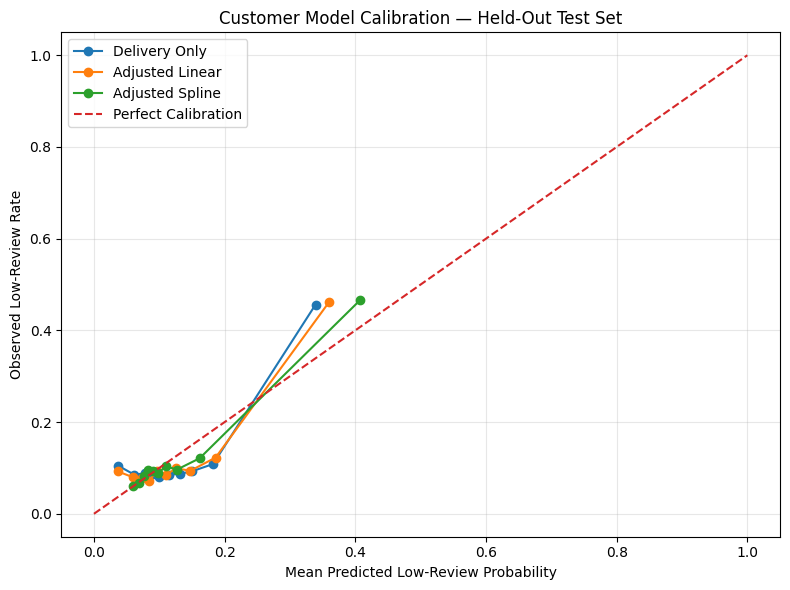

In [20]:
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss
)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Fit the adjusted spline model using training observations only.
# Explicit bounds allow prediction for test-set delays that fall
# outside the training sample's observed minimum and maximum.

delay_min = validation_data["delivery_delay_days"].min()
delay_max = validation_data["delivery_delay_days"].max()

spline_holdout_formula = (
    "low_review ~ "
    f"bs(delivery_delay_days, df=4, degree=3, "
    f"lower_bound={delay_min}, upper_bound={delay_max})"
    " + log_freight_percentage"
    " + C(category_group)"
    " + C(state_group)"
)

spline_holdout_fit = smf.glm(
    formula=spline_holdout_formula,
    data=train_data,
    family=sm.families.Binomial()
).fit(maxiter=100)

# Collect all three models
validation_models = {
    "Delivery Only": baseline_holdout_fit,
    "Adjusted Linear": adjusted_holdout_fit,
    "Adjusted Spline": spline_holdout_fit
}

y_test = test_data["low_review"]

model_predictions = {}
performance_results = []

# Evaluate all models on identical test observations
for name, model in validation_models.items():

    predictions = model.predict(test_data)

    predictions = np.clip(
        np.asarray(predictions),
        1e-8,
        1 - 1e-8
    )

    model_predictions[name] = predictions

    performance_results.append({
        "Model": name,
        "Test Orders": len(test_data),
        "Converged": model.converged,
        "ROC-AUC": roc_auc_score(
            y_test, predictions
        ),
        "Brier Score": brier_score_loss(
            y_test, predictions
        ),
        "Log Loss": log_loss(
            y_test, predictions
        ),
        "Mean Predicted %": predictions.mean() * 100,
        "Actual Low Review %": y_test.mean() * 100
    })

performance_comparison = pd.DataFrame(
    performance_results
)

print("Held-out model performance:")
display(performance_comparison.round(4))


# Plot calibration curves using 10 quantile-based bins
plt.figure(figsize=(8, 6))

for name, predictions in model_predictions.items():

    observed_rate, predicted_rate = calibration_curve(
        y_test,
        predictions,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted_rate,
        observed_rate,
        marker="o",
        label=name
    )

# Perfect-calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Low-Review Probability")
plt.ylabel("Observed Low-Review Rate")
plt.title("Customer Model Calibration — Held-Out Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Customer Model Validation: Findings

- **Nonlinearity:** Delivery delay has a nonlinear association with low reviews. The spline model fits substantially better than the original linear model.
- **Model Comparison:** Adding freight, product category, and customer state improved test ROC-AUC from 0.6581 to 0.6756.
- **Best Model:** The adjusted spline performed best (ROC-AUC = 0.6915, Brier = 0.0950, Log Loss = 0.3398).
- **Calibration:** Average predicted risk was close to the observed rate, but the models underestimated low reviews in the highest-risk group.
- **Limitations:** Predictive accuracy remains moderate, and the model primarily represents orders with completed delivery information.

### Conclusion
The adjusted spline is preferred for customer-risk prediction because it captures nonlinear delivery effects and performs best on held-out data. The original linear regression remains useful for explaining the general direction of the delivery-delay association, but its constant per-day odds ratio oversimplifies the relationship.

# Seller Model Validation

In [21]:
import statsmodels.api as sm

# Prepare seller features using Notebook 10 definitions

seller_validation = seller.copy()

seller_validation["seller_sales_per_order"] = (
    seller_validation["seller_total_sales"]
    / seller_validation["seller_order_count"].replace(0, np.nan)
)

seller_validation["seller_log_order_count"] = np.log1p(
    seller_validation["seller_order_count"]
)

seller_validation["log_product_count"] = np.log1p(
    seller_validation["seller_product_count"]
)

# Same predictors used in Notebook 10
quality_predictors = [
    "seller_late_delivery_rate",
    "log_product_count",
    "seller_category_count",
    "seller_log_order_count"
]

sales_predictors = [
    "log_product_count",
    "seller_category_count",
    "seller_log_order_count"
]

thresholds = [5, 10, 20]

quality_results = []
sales_results = []

seller_threshold_fits = {}

for threshold in thresholds:

    # ----------------------------
    # Seller-quality regression
    # ----------------------------

    quality_eligible = (
        (seller_validation["seller_reviewed_order_count"] >= threshold)
        & (seller_validation["seller_delivery_order_count"] >= threshold)
    )

    quality_data = (
        seller_validation.loc[
            quality_eligible,
            [
                "seller_average_review",
                "seller_reviewed_order_count"
            ] + quality_predictors
        ]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    X_quality = sm.add_constant(
        quality_data[quality_predictors]
    )

    y_quality = quality_data["seller_average_review"]

    quality_fit = sm.WLS(
        y_quality,
        X_quality,
        weights=quality_data["seller_reviewed_order_count"]
    ).fit(cov_type="HC3")

    late_term = "seller_late_delivery_rate"

    # Translate the late-rate coefficient into
    # a 10-percentage-point change
    late_effect = quality_fit.params[late_term] * 0.10
    late_ci = quality_fit.conf_int().loc[late_term] * 0.10

    quality_results.append({
        "Threshold": threshold,
        "Sellers": int(quality_fit.nobs),
        "R-squared": quality_fit.rsquared,
        "Effect per +10pp Late Rate": late_effect,
        "CI Lower": late_ci.iloc[0],
        "CI Upper": late_ci.iloc[1],
        "p-value": quality_fit.pvalues[late_term]
    })

    # ----------------------------
    # Seller-sales regression
    # ----------------------------

    sales_eligible = (
        seller_validation["seller_order_count"] >= threshold
    ) & (
        seller_validation["seller_sales_per_order"] > 0
    )

    sales_data = (
        seller_validation.loc[
            sales_eligible,
            ["seller_sales_per_order"] + sales_predictors
        ]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    sales_data["log_sales_per_order"] = np.log(
        sales_data["seller_sales_per_order"]
    )

    X_sales = sm.add_constant(
        sales_data[sales_predictors]
    )

    y_sales = sales_data["log_sales_per_order"]

    sales_fit = sm.OLS(
        y_sales,
        X_sales
    ).fit(cov_type="HC3")

    sales_results.append({
        "Threshold": threshold,
        "Sellers": int(sales_fit.nobs),
        "R-squared": sales_fit.rsquared,
        "Order Volume Coefficient":
            sales_fit.params["seller_log_order_count"],
        "Order Volume p-value":
            sales_fit.pvalues["seller_log_order_count"]
    })

    # Save models for later sensitivity checks
    seller_threshold_fits[threshold] = {
        "quality": quality_fit,
        "sales": sales_fit
    }


quality_threshold_results = pd.DataFrame(quality_results)
sales_threshold_results = pd.DataFrame(sales_results)

print("Seller-quality threshold sensitivity:")
display(quality_threshold_results.round(4))

print("\nSeller-sales threshold sensitivity:")
display(sales_threshold_results.round(4))

Seller-quality threshold sensitivity:


,Threshold,Sellers,R-squared,Effect per +10pp Late Rate,CI Lower,CI Upper,p-value
0,5,1739,0.2354,-0.2621,-0.2977,-0.2266,0.0
1,10,1215,0.2497,-0.2728,-0.3158,-0.2298,0.0
2,20,784,0.2610,-0.2843,-0.3377,-0.2309,0.0



Seller-sales threshold sensitivity:


,Threshold,Sellers,R-squared,Order Volume Coefficient,Order Volume p-value
0,5,1794,0.0067,-0.0496,0.0928
1,10,1271,0.0115,-0.0639,0.0507
2,20,818,0.0190,-0.0748,0.0641


**Finding:** The seller-quality relationship remained stable across eligibility thresholds of 5, 10, and 20 observations. A 10-percentage-point increase in late-delivery rate was associated with approximately 0.26–0.28 fewer review points. The seller-sales model continued to have very low explanatory power (R² < 0.02), with no statistically significant order-volume effect.

### Weighted vs. Unweighted Seller-Quality Regression


In [23]:
# Recreate the original 10-observation seller-quality sample

quality_data_10 = (
    seller_validation.loc[
        (seller_validation["seller_reviewed_order_count"] >= 10)
        & (seller_validation["seller_delivery_order_count"] >= 10),
        [
            "seller_average_review",
            "seller_reviewed_order_count"
        ] + quality_predictors
    ]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

X_quality_10 = sm.add_constant(
    quality_data_10[quality_predictors]
)

y_quality_10 = quality_data_10["seller_average_review"]

# Original weighted model
weighted_fit = seller_threshold_fits[10]["quality"]

# Fit an unweighted model using the same observations
unweighted_fit = sm.OLS(
    y_quality_10,
    X_quality_10
).fit(cov_type="HC3")


# Compare late-delivery effects
def summarize_quality_model(model, name):

    term = "seller_late_delivery_rate"
    ci = model.conf_int().loc[term]

    return {
        "Model": name,
        "Sellers": int(model.nobs),
        "Effect per +10pp Late Rate": model.params[term] * 0.10,
        "CI Lower": ci.iloc[0] * 0.10,
        "CI Upper": ci.iloc[1] * 0.10,
        "p-value": model.pvalues[term],
        "R-squared": model.rsquared
    }


weighting_comparison = pd.DataFrame([
    summarize_quality_model(
        weighted_fit,
        "Weighted (WLS)"
    ),
    summarize_quality_model(
        unweighted_fit,
        "Unweighted (OLS)"
    )
])

print("Weighted vs. unweighted seller-quality regression:")
display(weighting_comparison.round(4))

print(
    "\nSame seller sample:",
    int(weighted_fit.nobs) == int(unweighted_fit.nobs)
)

print(
    "Reviewed orders per seller:"
)
display(
    quality_data_10["seller_reviewed_order_count"]
    .describe()
    .round(2)
)

Weighted vs. unweighted seller-quality regression:


,Model,Sellers,Effect per +10pp Late Rate,CI Lower,CI Upper,p-value,R-squared
0,Weighted (WLS),1215,-0.2728,-0.3158,-0.2298,0.0,0.2497
1,Unweighted (OLS),1215,-0.2516,-0.2861,-0.2170,0.0,0.2398



Same seller sample: True
Reviewed orders per seller:


,seller_reviewed_order_count
count,1215.00
mean,74.27
std,153.18
min,10.00
25%,16.00
50%,30.00
75%,68.00
max,1807.00


**Finding:** The seller-quality relationship remained negative and statistically significant under both weighted and unweighted regression. A 10-percentage-point increase in late-delivery rate was associated with 0.273 fewer review points using WLS and 0.252 fewer points using OLS. The finding is robust to the weighting decision.

### Extreme Seller Sales-per-Order Sensitivity

In [24]:
# Recreate the original 10-order seller-sales sample

sales_data_10 = (
    seller_validation.loc[
        (seller_validation["seller_order_count"] >= 10)
        & (seller_validation["seller_sales_per_order"] > 0),
        ["seller_sales_per_order"] + sales_predictors
    ]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

sales_data_10["log_sales_per_order"] = np.log(
    sales_data_10["seller_sales_per_order"]
)

# Examine sales-per-order distribution
print("Seller sales-per-order distribution (BRL):")

display(
    sales_data_10["seller_sales_per_order"]
    .describe(percentiles=[0.01, 0.50, 0.95, 0.99])
    .round(2)
)

# Establish trimming boundaries
sales_lower = (
    sales_data_10["seller_sales_per_order"].quantile(0.01)
)

sales_upper = (
    sales_data_10["seller_sales_per_order"].quantile(0.99)
)

# Exclude extreme values
sales_trimmed_data = sales_data_10.loc[
    sales_data_10["seller_sales_per_order"].between(
        sales_lower,
        sales_upper
    )
].copy()

# Original seller-sales model
original_sales_fit = seller_threshold_fits[10]["sales"]

# Refit the same model on trimmed observations
X_sales_trimmed = sm.add_constant(
    sales_trimmed_data[sales_predictors]
)

y_sales_trimmed = sales_trimmed_data["log_sales_per_order"]

trimmed_sales_fit = sm.OLS(
    y_sales_trimmed,
    X_sales_trimmed
).fit(cov_type="HC3")

# Compare model-level results
sales_trim_model_results = pd.DataFrame([
    {
        "Model": "Original",
        "Sellers": int(original_sales_fit.nobs),
        "R-squared": original_sales_fit.rsquared
    },
    {
        "Model": "Trimmed (1%-99%)",
        "Sellers": int(trimmed_sales_fit.nobs),
        "R-squared": trimmed_sales_fit.rsquared
    }
])

# Compare every regression predictor
sales_coefficient_results = []

for predictor in sales_predictors:

    for name, fit in [
        ("Original", original_sales_fit),
        ("Trimmed", trimmed_sales_fit)
    ]:

        sales_coefficient_results.append({
            "Model": name,
            "Predictor": predictor,
            "Coefficient": fit.params[predictor],
            "p-value": fit.pvalues[predictor]
        })

sales_coefficient_results = pd.DataFrame(
    sales_coefficient_results
)

print("\nLower boundary (BRL):", round(sales_lower, 2))
print("Upper boundary (BRL):", round(sales_upper, 2))
print(
    "Sellers removed:",
    len(sales_data_10) - len(sales_trimmed_data)
)

print("\nModel comparison:")
display(sales_trim_model_results.round(4))

print("\nCoefficient comparison:")
display(sales_coefficient_results.round(4))

Seller sales-per-order distribution (BRL):


,seller_sales_per_order
count,1271.00
mean,160.33
std,181.35
min,10.47
1%,22.19
50%,111.00
95%,476.50
99%,896.43
max,2025.50



Lower boundary (BRL): 22.19
Upper boundary (BRL): 896.43
Sellers removed: 26

Model comparison:


,Model,Sellers,R-squared
0,Original,1271,0.0115
1,Trimmed (1%-99%),1245,0.0078



Coefficient comparison:


,Model,Predictor,Coefficient,p-value
0,Original,log_product_count,-0.0078,0.8377
1,Trimmed,log_product_count,-0.0194,0.5948
2,Original,seller_category_count,-0.0089,0.2486
3,Trimmed,seller_category_count,-0.0065,0.3723
4,Original,seller_log_order_count,-0.0639,0.0507
5,Trimmed,seller_log_order_count,-0.0389,0.2125


**Finding:** Removing 26 sellers with extreme sales per order reduced the seller-sales model's R² from 0.0115 to 0.0078. No predictors were statistically significant after trimming. The model has limited explanatory power, and its order-volume association is not robust to extreme-value removal.

### High-Volume Seller Influence


In [25]:
# Identify unusually high-volume sellers

review_count_cutoff = (
    quality_data_10["seller_reviewed_order_count"].quantile(0.99)
)

# Remove sellers above the 99th percentile
quality_trimmed = quality_data_10.loc[
    quality_data_10["seller_reviewed_order_count"]
    <= review_count_cutoff
].copy()

# Refit the original weighted seller-quality model
X_trimmed_quality = sm.add_constant(
    quality_trimmed[quality_predictors]
)

trimmed_quality_fit = sm.WLS(
    quality_trimmed["seller_average_review"],
    X_trimmed_quality,
    weights=quality_trimmed["seller_reviewed_order_count"]
).fit(cov_type="HC3")


# Compare the late-delivery relationship
def quality_stability_summary(model, label, data):

    term = "seller_late_delivery_rate"
    ci = model.conf_int().loc[term]

    predictions = model.predict(
        sm.add_constant(data[quality_predictors])
    )

    return {
        "Model": label,
        "Sellers": int(model.nobs),
        "Effect per +10pp Late Rate":
            model.params[term] * 0.10,
        "CI Lower": ci.iloc[0] * 0.10,
        "CI Upper": ci.iloc[1] * 0.10,
        "p-value": model.pvalues[term],
        "R-squared": model.rsquared,
        "Predictions Outside 1-5":
            int(((predictions < 1) | (predictions > 5)).sum())
    }


quality_stability_results = pd.DataFrame([
    quality_stability_summary(
        weighted_fit,
        "Original Weighted",
        quality_data_10
    ),
    quality_stability_summary(
        trimmed_quality_fit,
        "High-Volume Sellers Excluded",
        quality_trimmed
    )
])

print(
    "99th percentile reviewed-order count:",
    round(review_count_cutoff, 2)
)

print(
    "Sellers removed:",
    len(quality_data_10) - len(quality_trimmed)
)

print(
    "Share of reviewed orders removed (%):",
    round(
        (
            1 - quality_trimmed["seller_reviewed_order_count"].sum()
            / quality_data_10["seller_reviewed_order_count"].sum()
        ) * 100,
        2
    )
)

print("\nSeller-quality stability comparison:")
display(quality_stability_results.round(4))

99th percentile reviewed-order count: 856.14
Sellers removed: 13
Share of reviewed orders removed (%): 18.03

Seller-quality stability comparison:


,Model,Sellers,Effect per +10pp Late Rate,CI Lower,CI Upper,p-value,R-squared,Predictions Outside 1-5
0,Original Weighted,1215,-0.2728,-0.3158,-0.2298,0.0,0.2497,0
1,High-Volume Sellers Excluded,1202,-0.2742,-0.3163,-0.2320,0.0,0.2502,0


## Seller Model Validation: Findings

- **Eligibility Thresholds:** The seller-quality relationship remained stable across minimum thresholds of 5, 10, and 20 observations. A 10-percentage-point increase in late-delivery rate was associated with approximately 0.26–0.28 fewer review points.
- **Weighted vs. Unweighted:** Both methods showed a similar negative relationship (WLS: −0.273; OLS: −0.252 review points per 10-percentage-point increase).
- **Seller Sales:** Removing 26 extreme sellers reduced R² from 0.0115 to 0.0078. The sales model has limited explanatory power.
- **High-Volume Sellers:** Removing 13 sellers representing 18.03% of reviewed orders barely changed the late-delivery effect (−0.2728 vs. −0.2742).
- **Model Limitations:** Seller-quality findings are associations, not causal effects. The seller-sales predictors do not adequately explain differences in sales per order.

### Conclusion
The relationship between seller late-delivery rates and average customer reviews is consistent across the validation tests. The original weighted seller-quality model remains appropriate for the project. The seller-sales regression is substantially weaker and should be presented as an exploratory analysis rather than a strong predictive model.

# Final Validation and Error Analysis

In [26]:
from statsmodels.stats.multitest import multipletests

# Refit the preferred spline model with HC3 robust standard errors
# for consistency with the original adjusted linear model.

spline_robust_fit = smf.glm(
    formula=spline_formula,
    data=sensitivity_data,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3",
    maxiter=100
)

print("Spline model converged:", spline_robust_fit.converged)


# Apply FDR correction within each family of comparisons
def fdr_effect_table(model, variable):

    prefix = f"C({variable})[T."

    terms = [
        term for term in model.params.index
        if term.startswith(prefix)
    ]

    p_values = model.pvalues.loc[terms].to_numpy()

    significant, adjusted_p, _, _ = multipletests(
        p_values,
        alpha=0.05,
        method="fdr_bh"
    )

    confidence_intervals = model.conf_int().loc[terms]

    results = pd.DataFrame({
        "Group": [
            term.replace(prefix, "").rstrip("]")
            for term in terms
        ],
        "Odds Ratio": np.exp(
            model.params.loc[terms].to_numpy()
        ),
        "CI Lower": np.exp(
            confidence_intervals[0].to_numpy()
        ),
        "CI Upper": np.exp(
            confidence_intervals[1].to_numpy()
        ),
        "Original p-value": p_values,
        "FDR q-value": adjusted_p,
        "FDR Significant": significant
    })

    return results.sort_values("FDR q-value")


# Evaluate both model specifications
fdr_tables = {}

summary_rows = []

for model_name, fit in [
    ("Adjusted Linear", full_fit),
    ("Adjusted Spline", spline_robust_fit)
]:

    for group_type, variable in [
        ("Product Categories", "category_group"),
        ("Customer States", "state_group")
    ]:

        results = fdr_effect_table(fit, variable)

        fdr_tables[(model_name, group_type)] = results

        summary_rows.append({
            "Model": model_name,
            "Comparison Type": group_type,
            "Tests": len(results),
            "Significant Before FDR": int(
                (results["Original p-value"] < 0.05).sum()
            ),
            "Significant After FDR": int(
                results["FDR Significant"].sum()
            )
        })


fdr_summary = pd.DataFrame(summary_rows)

print("\nMultiple-comparison summary:")
display(fdr_summary)


# Examine categories and states relevant to earlier findings
focus_groups = {
    "Product Categories": [
        "office_furniture",
        "bed_bath_table",
        "luggage_accessories",
        "stationery"
    ],
    "Customer States": [
        "SP", "PR", "PA", "RJ"
    ]
}

for group_type, selected_groups in focus_groups.items():

    print(f"\n{group_type} — Adjusted Spline:")

    table = fdr_tables[("Adjusted Spline", group_type)]

    display(
        table.loc[
            table["Group"].isin(selected_groups)
        ].round(4)
    )

Spline model converged: True

Multiple-comparison summary:


,Model,Comparison Type,Tests,Significant Before FDR,Significant After FDR
0,Adjusted Linear,Product Categories,26,9,7
1,Adjusted Linear,Customer States,17,10,8
2,Adjusted Spline,Product Categories,26,10,9
3,Adjusted Spline,Customer States,17,6,6



Product Categories — Adjusted Spline:


,Group,Odds Ratio,CI Lower,CI Upper,Original p-value,FDR q-value,FDR Significant
17,office_furniture,2.0238,1.7193,2.3822,0.0000,0.0000,True
3,bed_bath_table,1.3266,1.2062,1.4590,0.0000,0.0000,True
22,stationery,0.7207,0.6097,0.8518,0.0001,0.0006,True
15,luggage_accessories,0.6535,0.5100,0.8373,0.0008,0.0029,True



Customer States — Adjusted Spline:


,Group,Odds Ratio,CI Lower,CI Upper,Original p-value,FDR q-value,FDR Significant
16,SP,0.7033,0.6316,0.7831,0.0000,0.0000,True
12,PR,0.7917,0.6895,0.9091,0.0009,0.0079,True
9,PA,1.1626,0.9475,1.4264,0.1489,0.2793,False
13,RJ,1.0448,0.9323,1.1708,0.4511,0.5140,False


**Finding:** After FDR correction, 9 of 26 product-category comparisons and 6 of 17 customer-state comparisons remained significant in the adjusted spline model. Office furniture and bed/bath/table had higher adjusted low-review odds than the reference category, while stationery and luggage/accessories had lower odds. São Paulo and Paraná showed lower odds than Bahia, but Pará and Rio de Janeiro were not significant against Bahia in the spline model.

### Reliability of Project Findings

| Finding | Assessment | Final Report Treatment |
|---|---|---|
| Delivery delay and customer dissatisfaction | Strong | Emphasize the nonlinear association and spline results |
| Seller late-delivery rate and average reviews | Strong | Emphasize the stable negative association |
| Product-category differences | Supported for selected categories | Report FDR-adjusted findings |
| Customer-state differences | Supported for selected states | Use spline results and specify comparison states |
| Freight percentage and low reviews | Tentative | Mention sensitivity to extreme freight values |
| Seller sales-per-order regression | Weak | Report limited explanatory power; avoid strong claims |
| Canceled and undelivered orders | Important limitation | Explain that these experiences are largely excluded from the customer model |

**Overall Assessment:** Delivery reliability is the strongest recurring factor associated with customer satisfaction and seller review performance. Selected product and geographic differences provide additional findings. Freight and seller-sales relationships require more cautious interpretation.

### Model Limitations and Necessary Revisions

#### Customer Model
- **Missing Data:** The model excludes 3,611 orders (3.63%), primarily those without delivery information. These exclusions include many canceled and undelivered orders with poor reviews.
- **Nonlinearity:** The original linear model oversimplifies delivery-delay effects. The adjusted spline model performed better on held-out data and should be preferred for customer-risk predictions.
- **Predictive Performance:** The spline model achieved ROC-AUC = 0.6915, indicating moderate predictive ability. It also underestimated dissatisfaction in the highest-risk group.
- **Freight:** The freight association was not statistically significant after trimming extreme freight values and should be treated cautiously.
- **Multiple Comparisons:** Product-category and customer-state findings should use FDR-adjusted results and clearly identify reference groups.

#### Seller Models
- **Seller Quality:** The negative association between late-delivery rates and reviews remained stable across validation tests, but it does not establish causation.
- **Seller Sales:** The sales-per-order regression had very low explanatory power (R² ≈ 0.01). Its predictors should not be presented as reliable explanations of seller revenue differences.
- **Seller Attribution:** Review and delivery metrics were attributed only to single-seller orders, excluding multi-seller orders from these measures.
- **Revenue Definition:** Seller sales represent item-price revenue, not profit or total customer payments.

#### Required Revisions for the Final Report
1. Use the adjusted spline model for customer-risk predictions while retaining the linear model as an interpretable comparison.
2. Emphasize validated delivery, product-category, and geographic findings.
3. Clearly explain missing-data exclusions and customer-model calibration limitations.
4. Present freight and seller-sales findings as exploratory or tentative.
5. Report associations rather than causal effects.
6. Acknowledge that the Olist dataset covers historical transactions from 2016–2018.

**Conclusion:** No calculation inconsistencies were identified during validation. The main limitations concern model specification, excluded orders, predictive performance, and the interpretation of statistical associations.

## Final Validation and Error-Analysis Summary

### Data Integrity
- All 34 data-integrity and calculation checks passed.
- No duplicate records, aggregation errors, or incorrect seller attribution were identified.
- The customer model retained 95,830 of 99,441 orders.

### Validated Customer Findings
- Delivery delay consistently showed a positive association with low reviews.
- The relationship was nonlinear, with dissatisfaction increasing more sharply for severe delays.
- The adjusted spline model performed best on held-out data (ROC-AUC = 0.6915; Brier Score = 0.0950).
- Selected product-category and geographic differences remained significant after FDR correction.
- The freight association was sensitive to extreme values and is less reliable.

### Validated Seller Findings
- Higher seller late-delivery rates were consistently associated with lower average review scores.
- This relationship remained stable across eligibility thresholds, weighting methods, and high-volume seller exclusions.
- The seller-sales regression had very low explanatory power (R² ≈ 0.01), limiting conclusions about sales performance.

### Remaining Limitations
- Excluded orders had substantially worse reviews, creating potential selection bias.
- The customer model primarily represents orders with valid delivery information.
- Customer-model discrimination was moderate, and calibration was imperfect for high-risk orders.
- Seller review and delivery measures exclude multi-seller orders.
- Results are observational and cannot establish causation.
- The dataset represents historical Brazilian e-commerce transactions from 2016–2018.

### Final Decisions
- **Customer Model:** Use the adjusted spline for predicted low-review probabilities. Retain the linear logistic model for comparison.
- **Seller Quality:** Retain the weighted regression as the primary seller-quality analysis.
- **Product and Geography:** Emphasize statistically supported comparisons after FDR correction.
- **Freight and Seller Sales:** Present cautiously as secondary or exploratory findings.
- **Business Recommendations:** Focus on delivery reliability, supported product-category differences, and relevant geographic patterns.

### Conclusion
Validation confirmed the consistency of the processed datasets and strengthened confidence in the main delivery-related findings. The analysis also identified weaker relationships and important limitations that must be addressed in the final interpretation and recommendations.